# Buổi A1: Máy học là gì? Dạy máy bằng ví dụ

**Câu chuyện.** Một phòng khám lưu sổ theo dõi **442 bệnh nhân**. Với mỗi người, sổ ghi chỉ số cơ thể lúc khám đầu (cân nặng so với chiều cao, huyết áp, xét nghiệm máu...) và một **điểm tiến triển bệnh sau đúng 1 năm** (số càng cao, bệnh càng nặng). Bác sĩ muốn biết: *nhìn chỉ số lúc khám đầu, có đoán trước được điểm sau 1 năm không?*

Mình thuê một cậu nhân viên học việc tên **Tí**. Tí đọc sổ cũ rồi đoán cho bệnh nhân mới. Cậu Tí đó chính là **máy học** (machine learning).

**Lưu ý:** đây là dữ liệu mẫu có sẵn trong thư viện scikit-learn để học, không dùng để chẩn đoán thật.

**Nhiệm vụ buổi này:** thấy tận mắt máy học làm việc, hiểu "học" nghĩa là gì, và tự chạy một dự đoán đầu tiên.

**Chuẩn bị:** chỉ cần Python có `numpy`, `pandas`, `matplotlib`, `scikit-learn`. Không cần tải file nào.

**Quy ước của cả khóa:** code (tên biến, tên cột, nhãn hình) viết bằng tiếng Anh, lời giải thích bằng tiếng Việt.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Chạy thử vài dòng: máy đoán được không? |
| Chặng 1 | Cách cũ: viết luật bằng tay thì ra sao? |
| Chặng 2 | Cách mới: để máy tự rút luật từ sổ cũ thì khác gì? |
| Chặng 3 | Máy "học" thực chất là học cái gì? |
| Chặng 4 | Đoán bệnh nhân chưa từng gặp: tin được đến đâu? |

## Chặng 0: Chạy thử trước, hiểu sau

**Câu hỏi:** chỉ với vài dòng code, máy có đoán được điểm tiến triển bệnh không?

Mình chạy trước để thấy thành quả. Mỗi dòng sẽ được mổ xẻ ngay bên dưới. Đầu tiên là chuẩn bị đồ nghề.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_diabetes
data = load_diabetes(as_frame=True, scaled=False)
patients = data.frame
patients.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


**Giải thích từng dòng**

- `from sklearn.datasets import load_diabetes`: lấy từ hộp đồ nghề scikit-learn (viết tắt `sklearn`) một hàm tên `load_diabetes`, hàm này mở sẵn bộ dữ liệu 442 bệnh nhân có kèm theo thư viện.
- `data = load_diabetes(as_frame=True, scaled=False)`: gọi hàm và cất kết quả vào biến `data`. Hai tùy chọn: `as_frame=True` nghĩa là trả dữ liệu dưới dạng bảng pandas cho dễ nhìn; `scaled=False` nghĩa là giữ **số gốc** (mặc định thư viện nén các số về cỡ rất nhỏ, khó hình dung, xem phần Tip pro cuối bài).
- `patients = data.frame`: lấy cái bảng ra khỏi `data` và đặt tên là `patients` (bệnh nhân). Bảng này giống một sheet Excel, trong pandas gọi là DataFrame.
- `patients.head()`: xem 5 dòng đầu. Dòng cuối của một cell tự được hiển thị, không cần `print`.

Mỗi dòng là **một bệnh nhân**. Các cột:

| Cột | Ý nghĩa |
|---|---|
| `age` | tuổi |
| `sex` | giới tính, mã hóa thành số 1 hoặc 2 |
| `bmi` | chỉ số khối cơ thể (cân nặng so với chiều cao, đơn vị kg/m²) |
| `bp` | huyết áp trung bình |
| `s1` đến `s6` | sáu chỉ số xét nghiệm máu |
| `target` | **điểm tiến triển bệnh sau 1 năm**, đây là thứ ta muốn đoán |

Buổi này mình chỉ dùng hai cột: `bmi` (làm đề bài) và `target` (làm đáp án). Trước khi nhờ máy, hãy xem hai cột đó trông ra sao:

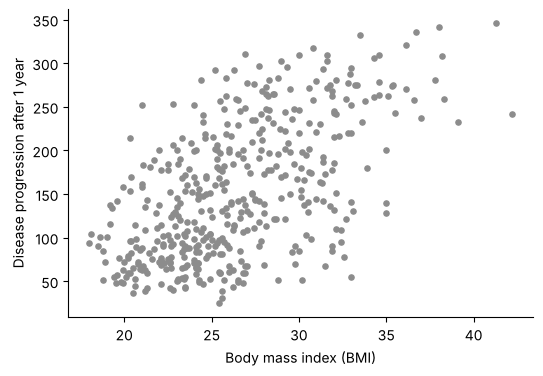

In [3]:
plt.scatter(patients["bmi"], patients["target"], s=14, color=GRAY)
plt.xlabel("Body mass index (BMI)")
plt.ylabel("Disease progression after 1 year")
plt.show()

**Giải thích từng dòng**

- `plt.scatter(patients["bmi"], patients["target"], s=14, color=GRAY)`: vẽ biểu đồ phân tán: mỗi bệnh nhân là một chấm. Hoành độ (trục ngang) là `bmi`, tung độ (trục dọc) là `target`. `s=14` là cỡ chấm, `color=GRAY` là màu xám.
- `plt.xlabel("Body mass index (BMI)")`: ghi tên trục ngang.
- `plt.ylabel("Disease progression after 1 year")`: ghi tên trục dọc.
- `plt.show()`: hiện hình ra màn hình.

**Cách đọc**

- **Con số:** 442 chấm, BMI trải từ khoảng 18 đến 42, điểm tiến triển từ 25 đến 346.
- **Bức tranh:** đám chấm trông như một đám mây dốc lên về bên phải: người có BMI cao thường có điểm tiến triển cao hơn. Nhưng đám mây rất *dày*: cùng một mức BMI mà điểm có thể chênh nhau cả trăm. BMI cho ta một xu hướng, không cho một đáp án chắc chắn.
- **Câu hỏi tiếp:** có thể kẻ một đường đi xuyên đám mây để làm "bản đồ" cho xu hướng đó không? Và ai kẻ, người hay máy?

Giờ đến lúc thuê Tí. Đề bài của Tí là cột `bmi`, đáp án là cột `target`.

In [4]:
from sklearn.linear_model import LinearRegression
X = patients[["bmi"]]
y = patients["target"]
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[10.23]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['bmi']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-117.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


**Giải thích từng dòng**

- `from sklearn.linear_model import LinearRegression`: lấy cỗ máy `LinearRegression` (hồi quy tuyến tính): cỗ máy chuyên đi tìm một **đường thẳng** đi xuyên đám mây điểm.
- `X = patients[["bmi"]]`: `X` là **đề bài** (các cột máy được phép nhìn). Hai cặp ngoặc vuông nghĩa là "một bảng nhỏ có 1 cột". Viết hoa `X` theo thói quen toán học: X là một bảng (nhiều dòng, nhiều cột).
- `y = patients["target"]`: `y` là **đáp án** (thứ cần đoán). Một cặp ngoặc vuông nghĩa là "một cột đơn". Viết thường `y` vì nó chỉ là một dãy số.
- `model = LinearRegression()`: mua một cỗ máy mới tinh, chưa học gì, đặt tên là `model`. Cậu Tí vừa nhận việc, đầu óc còn trống.
- `model.fit(X, y)`: `fit` nghĩa là "cho máy học": máy đọc 442 cặp (đề, đáp) và tự rút ra quy luật. Dòng chữ `LinearRegression()` hiện ra bên dưới chỉ là cái máy tự giới thiệu, không phải kết quả.

**Hai lưu ý về dữ liệu đưa vào máy** (sẽ gặp lại ở mọi buổi):

- `X` luôn phải là **bảng hai chiều** (kể cả khi chỉ có 1 cột), còn `y` là **một cột**. Quên cặp ngoặc vuông thứ hai là lỗi người mới gặp nhiều nhất.
- Với `LinearRegression`, `X` và `y` phải là **số** và **không được có ô trống (NaN)**. Bộ dữ liệu này đã sạch sẵn. Dữ liệu thật thì hiếm khi sạch, mình sẽ học cách xử lý ở buổi A2.

In [5]:
new_patient = pd.DataFrame({"bmi": [30]})
prediction = model.predict(new_patient)
print(f"BMI 30 -> predicted progression score: {prediction[0]:.0f}")

BMI 30 -> predicted progression score: 189


**Giải thích từng dòng**

- `new_patient = pd.DataFrame({"bmi": [30]})`: tạo bệnh nhân mới thành một bảng nhỏ: một dòng, cột `bmi` có giá trị 30. Tên cột phải **giống hệt** lúc học thì máy mới hiểu.
- `prediction = model.predict(new_patient)`: `predict` nghĩa là "đoán". Máy nhìn bệnh nhân mới, áp quy luật đã học, trả về một dãy kết quả (ở đây chỉ có 1 số).
- `print(f"BMI 30 -> predicted progression score: {prediction[0]:.0f}")`: in kết quả. `f"..."` cho phép nhét biến vào câu bằng cặp ngoặc nhọn. `prediction[0]` lấy số đầu tiên trong dãy. `:.0f` nghĩa là làm tròn đến số nguyên.

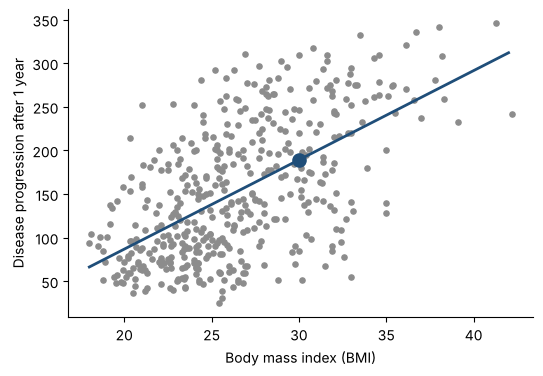

In [6]:
line_x = pd.DataFrame({"bmi": [18, 42]})
plt.scatter(X["bmi"], y, s=14, color=GRAY)
plt.plot(line_x["bmi"], model.predict(line_x), color=BLUE, linewidth=2)
plt.scatter([30], prediction, s=90, color=BLUE, zorder=3)
plt.xlabel("Body mass index (BMI)")
plt.ylabel("Disease progression after 1 year")
plt.show()

**Giải thích từng dòng**

- `line_x = pd.DataFrame({"bmi": [18, 42]})`: hai đầu mút của đường thẳng: BMI nhỏ nhất và lớn nhất trong sổ. Hai điểm là đủ để vẽ một đường thẳng.
- `plt.scatter(X["bmi"], y, s=14, color=GRAY)`: vẽ lại đám mây điểm như trước.
- `plt.plot(line_x["bmi"], model.predict(line_x), color=BLUE, linewidth=2)`: `plt.plot` vẽ **đường nối**. Máy đoán điểm cho hai đầu mút rồi nối lại, ra đường thẳng mà máy đã học. `linewidth=2` là độ dày nét.
- `plt.scatter([30], prediction, s=90, color=BLUE, zorder=3)`: chấm to màu xanh là dự đoán cho bệnh nhân mới (BMI 30). `zorder=3` bảo chấm này nằm **trên cùng**, không bị các chấm xám che.
- `plt.xlabel(...); plt.ylabel(...)`: ghi tên hai trục như trước.

**Cách đọc**

- **Con số:** với BMI 30, máy đoán điểm tiến triển khoảng 189.
- **Bức tranh:** đường xanh chính là "bản đồ xu hướng" mà máy tự kẻ ra. Muốn đoán cho một bệnh nhân mới, chỉ cần dóng từ BMI của họ lên đường xanh rồi đọc sang trục dọc. Tí chưa từng gặp đúng bệnh nhân này, nhưng vẫn trả lời được nhờ đường kẻ đó.
- **Điều đáng để ý:** đường xanh nằm giữa đám mây chứ không đi qua từng chấm. Máy không *thuộc lòng* 442 người, nó chỉ giữ lại *xu hướng chung*.
- **Câu hỏi tiếp:** đường đó tốt đến đâu? Nếu để một người tự kẻ bằng tay thì sao?

**Mang về chặng 0:** ba bước làm ra một dự đoán: *tạo máy, cho máy học (`fit`), bảo máy đoán (`predict`)*.

## Chặng 1: Cách cũ, viết luật bằng tay

**Câu hỏi:** trước khi có máy học, người ta làm thế nào?

Một bác sĩ lâu năm có thể nhìn đám mây điểm rồi tự đặt luật: *BMI dưới 23 thì đoán 100, từ 23 đến dưới 27 thì đoán 140, từ 27 trở lên thì đoán 200*. Đây là cách làm cũ: **người viết luật, máy chỉ chạy luật**.

In [7]:
def rule_predict(bmi):
    if bmi < 23:
        return 100
    elif bmi < 27:
        return 140
    else:
        return 200

**Giải thích từng dòng**

- `def rule_predict(bmi):`: `def` nghĩa là "tự định nghĩa một chức năng mới" tên `rule_predict`. Chức năng này nhận vào một con số `bmi` (đặt trong ngoặc tròn) rồi trả lời lại một con số. Dấu hai chấm cuối dòng báo hiệu phần thân chức năng nằm ở các dòng thụt vào bên dưới.
- `if bmi < 23:`: `if` nghĩa là "nếu": nếu BMI nhỏ hơn 23 thì làm dòng thụt vào ngay bên dưới.
- `return 100`: `return` nghĩa là "trả lời là": trả lời 100 rồi kết thúc, không đọc tiếp các dòng sau.
- `elif bmi < 27:`: `elif` là "nếu không thì nếu": chỉ kiểm tra khi điều kiện trước sai. Vậy dòng này nghĩa là BMI từ 23 đến dưới 27.
- `return 140`: trả lời 140 cho nhóm giữa.
- `else:`: `else` là "còn lại": mọi trường hợp chưa khớp luật nào ở trên, tức BMI từ 27 trở lên.
- `return 200`: trả lời 200 cho nhóm cuối.

In [8]:
rule_pred = patients["bmi"].apply(rule_predict)
rule_error = (y - rule_pred).abs().mean()
baseline_error = (y - y.mean()).abs().mean()
print(f"Guess the average for everyone: off by {baseline_error:.1f} points on average")
print(f"Hand-written rule:              off by {rule_error:.1f} points on average")

Guess the average for everyone: off by 65.8 points on average
Hand-written rule:              off by 54.1 points on average


**Giải thích từng dòng**

- `rule_pred = patients["bmi"].apply(rule_predict)`: `.apply(...)` chạy chức năng `rule_predict` lần lượt cho **từng** BMI trong cột, thu về một cột dự đoán dài 442 số.
- `rule_error = (y - rule_pred).abs().mean()`: tính **sai lệch trung bình**: lấy đáp án trừ dự đoán cho từng người (`y - rule_pred`), bỏ dấu âm (`.abs()`) vì lệch hụt hay lệch dư đều là lệch, rồi lấy trung bình (`.mean()`). Kết quả đọc là "trung bình đoán lệch bao nhiêu điểm".
- `baseline_error = (y - y.mean()).abs().mean()`: làm lại phép tính trên nhưng với cách đoán lười nhất: ai cũng đoán bằng điểm trung bình của cả sổ (`y.mean()`). Đây là **mốc so sánh**: luật nào không hơn mốc này thì vô dụng.
- `print(f"... {baseline_error:.1f} ...")`: in kết quả, làm tròn 1 chữ số thập phân. Hai dòng `print` có độ rộng căn thẳng hàng để dễ so.

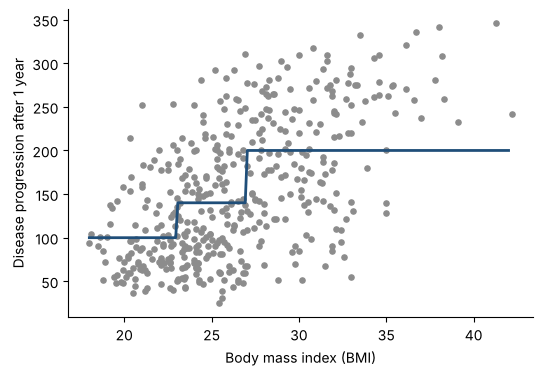

In [9]:
plt.scatter(X["bmi"], y, s=14, color=GRAY)
grid = np.linspace(18, 42, 200)
plt.plot(grid, [rule_predict(b) for b in grid], color=BLUE, linewidth=2)
plt.xlabel("Body mass index (BMI)")
plt.ylabel("Disease progression after 1 year")
plt.show()

**Giải thích từng dòng**

- `grid = np.linspace(18, 42, 200)`: `np.linspace(18, 42, 200)` sinh ra 200 con số cách đều nhau từ 18 đến 42, để vẽ đường mượt.
- `plt.plot(grid, [rule_predict(b) for b in grid], color=BLUE, linewidth=2)`: cho từng số `b` trong `grid` chạy qua `rule_predict` rồi nối lại. Đoạn `[... for b in grid]` là cách viết gọn "với mỗi b trong grid, tính rồi gom vào một danh sách".

**Cách đọc**

- **Con số:** đoán bừa bằng trung bình thì lệch khoảng 66 điểm; luật tay của ta lệch khoảng 54. Luật đã hơn mốc rõ rệt.
- **Bức tranh:** đường xanh là ba bậc thang. Bậc thang thô nên người nằm sát ranh giới (BMI 22,9 và 23,1) bị xếp vào hai nhóm khác hẳn nhau dù gần như giống nhau.
- **Điều khó chịu của cách cũ:** ba ngưỡng 23, 27 và ba mức 100, 140, 200 là *đoán mò* của người viết. Muốn tốt hơn phải ngồi thử đi thử lại. Nếu có 10 cột thay vì 1, số luật phải viết tăng chóng mặt, và ai cũng có thể viết khác nhau.

**Mang về chặng 1:** cách cũ là *người viết luật cho máy chạy*. Làm được, nhưng tốn công, khó tối ưu, và nản dần khi cột tăng lên.

## Chặng 2: Cách mới, để máy tự rút luật

**Câu hỏi:** máy học khác cách cũ ở điểm cốt lõi nào?

Hình dưới cho thấy sự khác nhau. Hai cách dùng *cùng ba thứ* (dữ liệu, luật, đáp án) nhưng **đảo vai**:

- **Cách cũ:** người đưa *dữ liệu + luật*, máy trả *đáp án*.
- **Máy học:** người đưa *dữ liệu + đáp án*, máy trả *luật*. Luật đó sau này dùng để đoán cho dữ liệu mới.

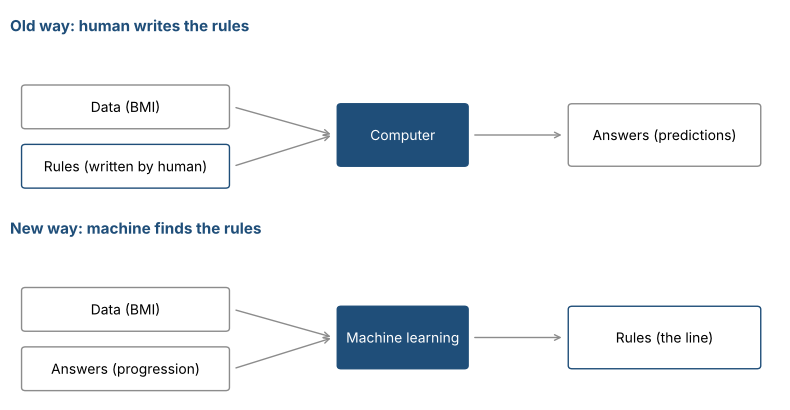

In [10]:
# Decorative diagram: just run it, no need to read the code line by line.
from matplotlib.patches import FancyBboxPatch
fig, axes = plt.subplots(2, 1, figsize=(8, 4.2))
def draw(ax, left, right, out, title, hi):
    ax.set_xlim(0, 10); ax.set_ylim(0, 3); ax.axis("off")
    ax.text(0, 2.75, title, fontsize=11, fontweight="bold", color=BLUE, va="center")
    for i, (txt, color) in enumerate(zip(left, [GRAY, GRAY])):
        y0 = 1.45 - i * 0.95
        ax.add_patch(FancyBboxPatch((0.2, y0 - 0.3), 2.6, 0.6, boxstyle="round,pad=0.05", fc="white", ec=hi[i]))
        ax.text(1.5, y0, txt, ha="center", va="center", fontsize=10)
        ax.annotate("", xy=(4.2, 1.0), xytext=(2.9, y0), arrowprops=dict(arrowstyle="->", color=GRAY))
    ax.add_patch(FancyBboxPatch((4.3, 0.55), 1.6, 0.9, boxstyle="round,pad=0.05", fc=BLUE, ec=BLUE))
    ax.text(5.1, 1.0, right, ha="center", va="center", fontsize=10, color="white")
    ax.annotate("", xy=(7.2, 1.0), xytext=(6.0, 1.0), arrowprops=dict(arrowstyle="->", color=GRAY))
    ax.add_patch(FancyBboxPatch((7.3, 0.55), 2.4, 0.9, boxstyle="round,pad=0.05", fc="white", ec=hi[2]))
    ax.text(8.5, 1.0, out, ha="center", va="center", fontsize=10)
draw(axes[0], ["Data (BMI)", "Rules (written by human)"], "Computer", "Answers (predictions)", "Old way: human writes the rules", [GRAY, BLUE, GRAY])
draw(axes[1], ["Data (BMI)", "Answers (progression)"], "Machine learning", "Rules (the line)", "New way: machine finds the rules", [GRAY, GRAY, BLUE])
plt.tight_layout(); plt.show()

Chỗ được ô viền xanh đậm chính là *thứ do ai tạo ra*: ở cách cũ, luật do người viết; ở máy học, luật do máy rút ra từ ví dụ. Giờ so tay nghề: máy với luật tay của ta, cùng thước đo như ở chặng 1.

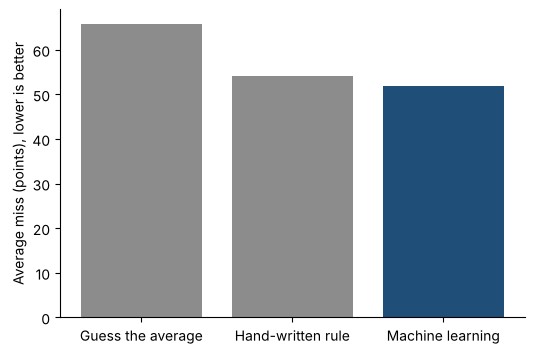

In [11]:
model_pred = model.predict(X)
model_error = (y - model_pred).abs().mean()
names = ["Guess the average", "Hand-written rule", "Machine learning"]
errors = [baseline_error, rule_error, model_error]
plt.bar(names, errors, color=[GRAY, GRAY, BLUE])
plt.ylabel("Average miss (points), lower is better")
plt.show()

**Giải thích từng dòng**

- `model_pred = model.predict(X)`: cho máy đoán lại **toàn bộ** 442 bệnh nhân trong sổ (không chỉ một người như ở chặng 0).
- `model_error = (y - model_pred).abs().mean()`: cùng phép tính sai lệch trung bình như chặng 1, nhưng với dự đoán của máy.
- `names = ["Guess the average", "Hand-written rule", "Machine learning"]`: tên ba cách đoán, đặt trong một danh sách để làm nhãn cho cột.
- `errors = [baseline_error, rule_error, model_error]`: ba sai lệch tương ứng, cùng thứ tự với tên.
- `plt.bar(names, errors, color=[GRAY, GRAY, BLUE])`: `plt.bar` vẽ **biểu đồ cột**: mỗi tên một cột cao bằng sai lệch của nó. Máy tô xanh, hai cách còn lại tô xám.
- `plt.ylabel("Average miss (points), lower is better")`: ghi tên trục dọc, nhắc rằng cột càng thấp càng tốt.

**Cách đọc**

- **Con số:** đoán trung bình lệch khoảng 66 điểm, luật tay lệch khoảng 54, máy lệch khoảng 52. Máy nhỉnh hơn, nhưng không áp đảo.
- **Bức tranh:** mình đã thử *vét cạn* hàng chục nghìn tổ hợp ngưỡng và mức cho luật ba bậc: luật tay tốt nhất cũng chỉ xuống khoảng 52, ngang máy. Vậy máy hơn ở đâu? Không phải ở độ chính xác với một cột, mà ở chỗ máy tìm ra mức đó **trong chớp mắt, không cần ai đoán ngưỡng**. Khi có 10 cột thay vì 1, số tổ hợp luật nổ tung, người hết đường thử, còn máy vẫn làm tiếp được.
- **Sự thật thà cần nói ngay:** lệch 52 điểm trên một thang có trung bình 152 vẫn là khá nhiều. Lý do không phải máy dở, mà là *chỉ một cột BMI chưa đủ thông tin* để đoán chính xác. Các buổi sau mình sẽ cho máy nhìn thêm nhiều cột.
- **Một lưu ý quan trọng:** ta đang chấm máy trên chính những bệnh nhân nó đã học. Giống như cho học sinh thi lại đúng đề đã làm: điểm sẽ đẹp hơn thực tế. Buổi A4 sẽ dạy cách chấm công bằng.

**Mang về chặng 2:** máy học là *đưa ví dụ (đề + đáp án), nhận về luật*. Thắng cách cũ ở chỗ tự tìm luật, tự tối ưu và mở rộng được khi dữ liệu nhiều cột.

## Chặng 3: Máy "học" thực chất là học cái gì?

**Câu hỏi:** bên trong `fit`, máy học ra thứ gì, và học bằng cách nào?

Đường thẳng nào cũng có công thức dạng: **điểm đoán = độ dốc × BMI + mốc nền**. Chỉ có hai con số cần tìm: độ dốc và mốc nền. "Học" nghĩa là *tìm hai con số này sao cho đường thẳng bám sát đám mây nhất*.

In [12]:
slope = model.coef_[0]
intercept = model.intercept_
print(f"progression = {slope:.2f} x BMI + ({intercept:.1f})")

progression = 10.23 x BMI + (-117.8)


**Giải thích từng dòng**

- `slope = model.coef_[0]`: `coef_` (hệ số) là thứ máy học được, có đuôi gạch dưới `_` là quy ước của sklearn cho "thứ chỉ có sau khi `fit`". Nó là một dãy số, mỗi cột của `X` một số; `[0]` lấy số đầu tiên (ta chỉ có 1 cột). Đây là **độ dốc**.
- `intercept = model.intercept_`: `intercept_` (hệ số chặn) cũng chỉ có sau `fit`. Đây là **mốc nền**: điểm đoán khi BMI bằng 0.
- `print(f"progression = {slope:.2f} x BMI + ({intercept:.1f})")`: in công thức máy học được. `:.2f` làm tròn 2 chữ số thập phân.

**Cách đọc**

- **Độ dốc khoảng 10,2:** BMI tăng thêm 1 đơn vị thì điểm đoán tăng khoảng 10 điểm. Đây là con số mang ý nghĩa thực tế nhất của mô hình.
- **Mốc nền khoảng -118:** nghĩa là một người có BMI bằng 0 sẽ có điểm -118. Vô nghĩa vì không ai có BMI bằng 0! Mốc nền chỉ là cái "neo" để đường thẳng đặt đúng độ cao. Đừng cố đọc ý nghĩa đời thực của nó khi 0 nằm ngoài vùng dữ liệu.

Vậy máy tìm hai con số này bằng cách nào? Hãy tự làm thay máy: thử vài đường thẳng và chấm điểm từng đường.

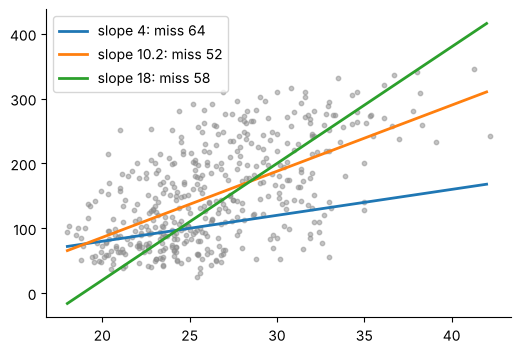

In [13]:
guesses = [(4, 0), (10.2, -118), (18, -340)]
for slope_g, intercept_g in guesses:
    miss = (y - (slope_g * X["bmi"] + intercept_g)).abs().mean()
    plt.plot(grid, slope_g * grid + intercept_g, label=f"slope {slope_g}: miss {miss:.0f}", linewidth=2)
plt.scatter(X["bmi"], y, s=10, color=GRAY, alpha=0.5)
plt.legend(); plt.show()

**Giải thích từng dòng**

- `guesses = [(4, 0), (10.2, -118), (18, -340)]`: ba đường thử, mỗi đường là một cặp (độ dốc, mốc nền): một đường quá thoải, một đường là đường máy tìm ra, một đường quá dốc.
- `for slope_g, intercept_g in guesses:`: lặp qua từng cặp, tách hai số ra hai biến.
- `miss = (y - (slope_g * X["bmi"] + intercept_g)).abs().mean()`: tính sai lệch trung bình của đường đang thử: đoán = độ dốc × BMI + mốc nền, rồi cùng phép tính như chặng 1.
- `plt.plot(grid, slope_g * grid + intercept_g, label=f"slope {slope_g}: miss {miss:.0f}", linewidth=2)`: vẽ đường đang thử, kèm nhãn (`label`) ghi độ dốc và sai lệch của nó. Mỗi vòng lặp sẽ tự được một màu mới.
- `plt.scatter(X["bmi"], y, s=10, color=GRAY, alpha=0.5)`: đám mây điểm vẽ mờ (`alpha=0.5` là nửa trong suốt) để không che các đường.
- `plt.legend(); plt.show()`: `plt.legend()` hiện bảng chú giải từ các nhãn đã đặt, rồi hiện hình.

**Cách đọc:** đường quá thoải và đường quá dốc đều lệch xa đám mây, sai lệch cao; đường giữa bám sát nhất, sai lệch thấp nhất. Việc máy làm khi `fit` chỉ là thử rất nhiều đường như thế một cách thông minh rồi chọn đường tốt nhất.

Để thấy rõ hơn, mình thử hàng trăm độ dốc và xem sai lệch thay đổi thế nào.

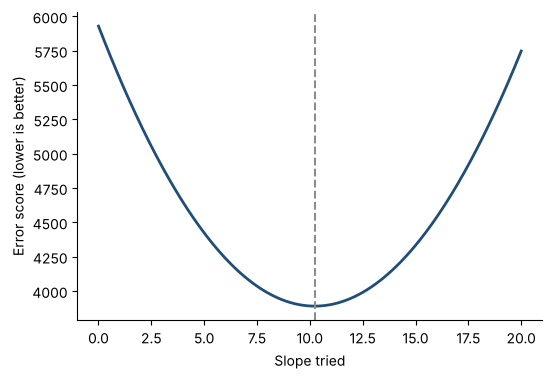

In [14]:
slopes = np.linspace(0, 20, 201)
scores = []
for s in slopes:
    b = (y - s * X["bmi"]).mean()
    scores.append(((y - (s * X["bmi"] + b)) ** 2).mean())
plt.plot(slopes, scores, color=BLUE, linewidth=2)
plt.axvline(slope, color=GRAY, linestyle="--")
plt.xlabel("Slope tried")
plt.ylabel("Error score (lower is better)")
plt.show()

**Giải thích từng dòng**

- `slopes = np.linspace(0, 20, 201)`: 201 độ dốc cách đều nhau từ 0 đến 20 để thử.
- `scores = []`: một danh sách trống để cất điểm sai lệch của từng độ dốc.
- `for s in slopes:`: với mỗi độ dốc `s`...
- `b = (y - s * X["bmi"]).mean()`: ...chọn mốc nền hợp lý nhất cho độ dốc đó (mốc nền làm cho sai lệch trung bình dương và âm triệt tiêu nhau).
- `scores.append(((y - (s * X["bmi"] + b)) ** 2).mean())`: ...tính điểm sai lệch rồi `append` (thêm vào cuối danh sách). Ở đây dùng thước đo là **trung bình của bình phương sai lệch** (mỗi lần lệch bị bình phương nên lệch càng to càng bị phạt nặng). Đó chính là thước máy dùng khi học; buổi B1 sẽ giải thích vì sao.
- `plt.axvline(slope, color=GRAY, linestyle="--")`: `axvline` kẻ một đường **thẳng đứng** nét đứt tại độ dốc mà máy đã chọn, để so với đáy chiếc bát.
- `plt.xlabel("Slope tried")`: ghi tên trục ngang.

**Cách đọc**

- **Con số:** đường cong có một điểm thấp nhất, và nét đứt (độ dốc máy chọn) nằm đúng đáy.
- **Bức tranh:** hãy hình dung một chiếc bát. Mỗi độ dốc là một vị trí trên thành bát, độ cao là mức sai lệch. Máy giống một viên bi thả vào bát: lăn xuống tới đáy thì dừng, ở đó sai lệch nhỏ nhất. "Học" chính là *lăn xuống đáy chiếc bát*.
- **Điều đáng nhớ:** mô hình càng phức tạp thì chiếc bát càng nhiều chiều và nhiều chỗ lõm, nhưng ý tưởng vẫn y vậy: *thử, đo sai lệch, chỉnh để sai lệch giảm*. Từ hồi quy tuyến tính đến mạng nơ-ron, bản chất của "học" không đổi.

**Mang về chặng 3:** học là *tìm các con số bên trong mô hình* (ở đây là độ dốc và mốc nền) sao cho sai lệch nhỏ nhất. Những con số học được nằm trong các thuộc tính có gạch dưới như `coef_`, `intercept_`.

## Chặng 4: Đoán bệnh nhân chưa từng gặp, tin được đến đâu?

**Câu hỏi:** máy trả lời cho mọi BMI, kể cả những giá trị lạ. Ta nên tin đến mức nào?

In [15]:
tests = pd.DataFrame({"bmi": [20, 25, 30, 35, 60]})
tests["predicted"] = model.predict(tests).round(0)
tests

,bmi,predicted
0,20,87.0
1,25,138.0
2,30,189.0
3,35,240.0
4,60,496.0


**Giải thích từng dòng**

- `tests = pd.DataFrame({"bmi": [20, 25, 30, 35, 60]})`: bảng năm bệnh nhân giả định với BMI khác nhau, trong đó có một người BMI 60 (rất cao, ngoài dữ liệu).
- `tests["predicted"] = model.predict(tests).round(0)`: thêm cột mới `predicted` bằng dự đoán của máy, làm tròn đến số nguyên bằng `.round(0)`.
- `tests`: hiện bảng.

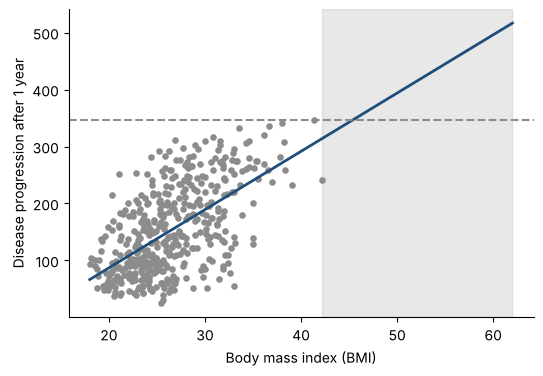

In [16]:
plt.scatter(X["bmi"], y, s=14, color=GRAY)
wide_x = pd.DataFrame({"bmi": [18, 62]})
plt.plot(wide_x["bmi"], model.predict(wide_x), color=BLUE, linewidth=2)
plt.axvspan(X["bmi"].max(), 62, color=GRAY, alpha=0.2)
plt.axhline(y.max(), color=GRAY, linestyle="--")
plt.xlabel("Body mass index (BMI)")
plt.ylabel("Disease progression after 1 year")
plt.show()

**Giải thích từng dòng**

- `wide_x = pd.DataFrame({"bmi": [18, 62]})`: hai đầu mút mới, kéo đường thẳng dài ra tới BMI 62 (xa hơn nhiều so với dữ liệu).
- `plt.axvspan(X["bmi"].max(), 62, color=GRAY, alpha=0.2)`: `axvspan` tô một **dải đứng**: từ BMI lớn nhất trong sổ (42) đến 62. Vùng xám nhạt này là vùng *máy chưa từng thấy ai*.
- `plt.axhline(y.max(), color=GRAY, linestyle="--")`: `axhline` kẻ một đường **ngang** nét đứt tại điểm tiến triển cao nhất từng thấy trong sổ (346).

**Cách đọc**

- **Con số:** với BMI từ 20 đến 35, máy đoán lần lượt khoảng 87, 138, 189, 240: tăng đều, hợp lý. Nhưng với BMI 60, máy đoán gần 500, cao hơn hẳn điểm cao nhất mà cả sổ từng có (346).
- **Bức tranh:** đường thẳng không biết dừng. Máy chỉ biết kéo đường đi tiếp, không biết rằng vùng xám kia nó chưa hề quan sát ai. Đoán *trong* vùng đã thấy gọi là **nội suy** (interpolation), đáng tin hơn nhiều so với đoán *ngoài* vùng đã thấy, gọi là **ngoại suy** (extrapolation).
- **Quy tắc thực hành:** trước khi tin một dự đoán, hỏi *"bệnh nhân này có giống những người máy đã học không?"* Nếu không, đừng tin con số.

**Mang về chặng 4:** máy đoán tốt khi dữ liệu mới *giống* dữ liệu cũ. Ngoài vùng đã thấy, kết quả có thể vô lý mà máy không hề báo lỗi.

### Từ vựng của máy học, gói gọn trong 1 bảng

Những từ này sẽ lặp lại ở mọi buổi, nên mình gom lại một lần cho dễ nhớ.

| Cách nói đời thường | Thuật ngữ | Trong buổi này |
|---|---|---|
| Đề bài | đặc trưng (feature) | cột `bmi`, biến `X` |
| Đáp án | nhãn (label, target) | cột `target`, biến `y` |
| Sổ cũ có sẵn đáp án | dữ liệu huấn luyện | 442 bệnh nhân |
| Cho máy đọc sổ để rút luật | huấn luyện (train, fit) | `model.fit(X, y)` |
| Máy trả lời cho ca mới | dự đoán (predict) | `model.predict(...)` |
| Học từ ví dụ **có** đáp án | học có giám sát (supervised learning) | cả buổi này |
| Đáp án là một con số | bài toán hồi quy (regression) | điểm tiến triển |

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Ba bước làm ra một dự đoán: tạo máy, `fit`, `predict`. `X` là bảng, `y` là một cột. |
| 1 | Cách cũ là người viết luật cho máy chạy: tốn công, khó tối ưu, nản khi nhiều cột. |
| 2 | Máy học là đưa ví dụ (đề + đáp án) và nhận về luật. Luôn so với một mốc đơn giản. |
| 3 | "Học" là tìm các con số bên trong mô hình (`coef_`, `intercept_`) sao cho sai lệch nhỏ nhất, như bi lăn xuống đáy bát. |
| 4 | Đoán trong vùng đã thấy thì đáng tin, ngoài vùng đã thấy có thể vô lý. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Cậu nhân viên học việc Tí | mô hình (model) | `LinearRegression()` |
| Cho Tí đọc sổ cũ | huấn luyện (fit) | `model.fit(X, y)` |
| Hỏi Tí về ca mới | dự đoán (predict) | `model.predict(...)` |
| Độ nghiêng của đường kẻ | hệ số (coefficient) | `model.coef_` |
| Độ cao của đường kẻ | hệ số chặn (intercept) | `model.intercept_` |
| Đoán lệch bao nhiêu điểm | sai lệch trung bình (MAE) | `(y - pred).abs().mean()` |
| Cách đoán lười nhất để làm mốc | mốc cơ sở (baseline) | `y.mean()` |

**Thử thách tự làm**

1. Đổi BMI của bệnh nhân mới thành 22 rồi 35 và chạy lại. Dự đoán thay đổi bao nhiêu mỗi lần, có khớp với độ dốc 10,2 không? (Gợi ý: hiệu hai dự đoán chia cho hiệu hai BMI.)
2. Thay cột `bmi` bằng cột `bp` (huyết áp) trong `X`, chạy lại từ `fit` đến biểu đồ cột sai lệch. Cột nào giúp máy đoán chính xác hơn? (Gợi ý: nhớ đổi tên cột trong `new_patient` và `line_x`.)
3. Sửa ba ngưỡng và ba mức trong `rule_predict` để sai lệch trung bình xuống dưới 53. Bạn mất bao nhiêu lần thử, so với đúng 1 lần `fit` của máy? (Gợi ý: thử ngưỡng 24,5 và 27,5, mức 90, 140, 220 sẽ cho khoảng 52,2.)

**Checklist năng lực** (tự tick khi làm được)

- [ ] Kể được máy học khác cách viết luật bằng tay ở điểm nào.
- [ ] Viết được ba bước: tạo máy, `fit`, `predict`.
- [ ] Phân biệt được `X` (bảng đề bài) và `y` (cột đáp án).
- [ ] Đọc được `coef_` và `intercept_` bằng lời đời thường.
- [ ] Giải thích được vì sao ngoài vùng dữ liệu đã thấy thì không nên tin dự đoán.

## Phần thưởng (Tip pro): Vì sao bộ dữ liệu mặc định lại có số bé xíu?


Khi gọi `load_diabetes()` mà **không** có `scaled=False`, thư viện trả về các cột đã được *chuẩn hóa*: trừ trung bình và co lại sao cho mỗi cột đều quanh số 0. Lý do là nhiều mô hình học tốt hơn khi các cột có cùng thang đo. Buổi B4 sẽ dạy riêng chuyện này. Ở buổi đầu mình dùng `scaled=False` để các con số còn mang ý nghĩa đời thực (BMI 30, không phải 0,05).

Chạy ô dưới để thấy sự khác biệt:

In [17]:
load_diabetes(as_frame=True).frame.head(3)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0


**Giải thích từng dòng**

- `load_diabetes(as_frame=True).frame.head(3)`: gọi lại hàm nhưng bỏ `scaled=False` (tức dùng mặc định `scaled=True`), lấy bảng và xem 3 dòng đầu. So với bảng ở chặng 0: các cột `age`, `bmi`, `bp`... nay là những số nhỏ quanh 0, còn `target` vẫn giữ nguyên.